# 04 · Final Training: 5-fold Cross-validation and Ensemble
## DSA 4050-XA CAT 2: Image Classification with PyTorch

| | |
|---|---|
| **Course** | DSA 4050-XA: Deep Learning, USIU-Africa (Fall 2026) |
| **Lecturer** | Dr. Alex Wambua |
| **Student** | Selmah Tzindori (669602) |
| **Notebook** | `04_final_training.ipynb` |
| **CAT requirement** | 4) accuracy |

### Objective
Train the final models with the settings chosen in notebook 03, measure their accuracy **honestly**, and predict the 46,000 test images.

1. **5-fold cross-validation.** Each model is trained 5 times, each time holding out a different fifth of the labelled data. Every one of the 4,000 labelled images is therefore predicted exactly once by a model that never saw it: the **out-of-fold (OOF) accuracy**. This is a fair estimate of test accuracy, unlike the fold-0 score that was used to *choose* the settings.
2. **Two architectures.** The tuned **ViT-Small** (main model) and **ConvNeXt-Tiny** (the runner-up in screening, with the same settings). Their errors partly differ, so averaging them can help. The OOF accuracy decides whether the second model is kept.
3. **Ensemble and test-time augmentation (TTA).** The test prediction is the average of all fold models, each predicting both the image and its mirror image.

### Inputs
- `best_params.json` (notebook 03), `train_folds.csv` (notebook 01), images

### Outputs
| File | Purpose |
|---|---|
| `models/folds/<model>_fold<k>_{oof,test}.npy` | Probabilities of each fold model (saved as soon as each fold finishes) |
| `models/folds/<model>_fold<k>.pt` | Fold model weights (half precision) |
| `data/processed/test_probs_ensemble.npy` | Final test probabilities (used by notebook 05) |
| `outputs/submission/submission.csv` | **Predictions in `Test.csv` format** |
| `outputs/tables/04_*`, `outputs/figures/04_*` | CV results, confusion matrix, mistakes |

**Runtime (T4):** ≈ 20 min (ViT) + ≈ 30 min (ConvNeXt). Each fold is saved the moment it finishes; if Colab disconnects, **re-run all** and finished folds are skipped.

## 0 · Setup

In [1]:
# =============================================================================
# STANDARD SETUP CELL
# =============================================================================
from google.colab import drive
drive.mount("/content/drive")

import sys
sys.path.insert(0, "/content/drive/MyDrive/DSA4050/cat2-image-classification/src")

import importlib
import cat2_utils as cu
importlib.reload(cu)
cu.set_seed()

NOTEBOOK = "04_final_training"
PATHS = cu.PATHS
print("Project root:", cu.PROJECT_ROOT)

Mounted at /content/drive
Random seed set to 42
Project root: /content/drive/MyDrive/DSA4050/cat2-image-classification


In [2]:
!pip install -q timm

In [3]:
import os, json, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, timm
from sklearn.metrics import confusion_matrix, classification_report
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})

DATA_SOURCE = "/content/drive/MyDrive/Advanced ML"      # the lecturer's shared folder (shortcut)
DATA_DIR = Path(cu.restore_data(DATA_SOURCE))
folds = pd.read_csv(os.path.join(PATHS["processed"], "train_folds.csv"))
test_df = pd.read_csv(DATA_DIR / "Test.csv")

X = cu.load_images(folds["id"], DATA_DIR / "train")
cache = DATA_DIR / "test_images.npy"                    # reading 46,000 PNGs takes ~1 min: cache them
if cache.exists():
    X_test = np.load(cache)
else:
    X_test = cu.load_images(test_df["id"], DATA_DIR / "train"); np.save(cache, X_test)
y = folds["target"].to_numpy()
FOLD_DIR = os.path.join(PATHS["models"], "folds"); os.makedirs(FOLD_DIR, exist_ok=True)
print("train", X.shape, "| test", X_test.shape, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

Source folder: /content/drive/MyDrive/Advanced ML
Unzipped 50,000 images to /content/cat2_data/train
train (4000, 32, 32, 3) | test (46000, 32, 32, 3) | GPU: Tesla T4


## 1 · Final configuration
The settings come straight from the Optuna search (`best_params.json`). ConvNeXt-Tiny reuses them; it was not tuned separately, so it is a second opinion, not a second search.

**Epochs:** 10, the same budget used in the search, so the tuned learning-rate schedule is applied exactly as it was evaluated. The **last-epoch** weights are used (the cosine schedule ends at a learning rate of ~0), not the best epoch. Picking the best epoch on the validation fold would make the OOF accuracy optimistic again.

In [4]:
with open(os.path.join(PATHS["processed"], "best_params.json")) as f:
    best = json.load(f)
EPOCHS = 10
PRETRAINED = True
N_FOLDS = folds["fold"].nunique()
SAVE_WEIGHTS = True                                     # ~45-55 MB per fold model on Drive
HP_KEYS = ["lr", "weight_decay", "label_smoothing", "randaug_magnitude", "erase_prob", "drop_path_rate", "warmup_epochs"]
MODELS = {
    "vit_small":     {"backbone": best["backbone"], **{k: best[k] for k in HP_KEYS}},
    "convnext_tiny": {"backbone": "convnext_tiny.fb_in22k_ft_in1k", **{k: best[k] for k in HP_KEYS}},
}
IMG_SIZE, BATCH = best["img_size"], best["batch_size"]
pd.DataFrame(MODELS).T

,backbone,lr,weight_decay,label_smoothing,randaug_magnitude,erase_prob,drop_path_rate,warmup_epochs
vit_small,vit_small_patch16_224.augreg_in21k_ft_in1k,0.000092,0.093117,0.196151,8,0.212491,0.001476,0
convnext_tiny,convnext_tiny.fb_in22k_ft_in1k,0.000092,0.093117,0.196151,8,0.212491,0.001476,0


## 2 · Training: 2 models × 5 folds
For each fold *k*: train on the other four folds (3,200 images), then predict
- fold *k* (800 images) → **out-of-fold** probabilities,
- all 46,000 test images → **test** probabilities.

Both use TTA (average of the image and its mirror image).

In [5]:
def make_model(backbone, drop_path_rate):
    kwargs = {"drop_path_rate": drop_path_rate} if "resnet" not in backbone else {}
    return timm.create_model(backbone, pretrained=PRETRAINED, num_classes=10, **kwargs)


eval_tf = cu.build_transforms(False, IMG_SIZE)
test_loader = cu.make_loader(cu.CIFARCSVDataset(test_df, images=X_test, transform=eval_tf), 256, shuffle=False)


def run_fold(name, cfg, k):
    """Train one fold model; save and return its out-of-fold and test probabilities."""
    f_oof, f_test = (os.path.join(FOLD_DIR, f"{name}_fold{k}_{s}.npy") for s in ("oof", "test"))
    if os.path.exists(f_oof) and os.path.exists(f_test):
        print(f"{name} fold {k}: already done, loading"); return np.load(f_oof), np.load(f_test)
    cu.set_seed(cu.SEED + k)
    tr, va = (folds["fold"] != k).to_numpy(), (folds["fold"] == k).to_numpy()
    train_ds = cu.CIFARCSVDataset(folds[tr], images=X[tr],
                                  transform=cu.build_transforms(True, IMG_SIZE, cfg["randaug_magnitude"], cfg["erase_prob"]))
    val_ds = cu.CIFARCSVDataset(folds[va], images=X[va], transform=eval_tf)
    tl, vl = cu.make_loader(train_ds, BATCH, shuffle=True), cu.make_loader(val_ds, 256, shuffle=False)
    model = make_model(cfg["backbone"], cfg["drop_path_rate"])
    t0 = time.time()
    res = cu.train_model(model, tl, vl, epochs=EPOCHS, lr=cfg["lr"], weight_decay=cfg["weight_decay"],
                         label_smoothing=cfg["label_smoothing"], warmup_epochs=cfg["warmup_epochs"], verbose=False)
    oof = cu.predict_proba(model, vl, tta=True)            # last-epoch weights
    test = cu.predict_proba(model, test_loader, tta=True)
    np.save(f_oof, oof); np.save(f_test, test)
    res["history"].to_csv(os.path.join(PATHS["logs"], f"history_{name}_fold{k}.csv"), index=False)
    if SAVE_WEIGHTS:
        torch.save({k_: v.half() for k_, v in model.state_dict().items()}, os.path.join(FOLD_DIR, f"{name}_fold{k}.pt"))
    acc = (oof.argmax(1) == y[va]).mean()
    print(f"{name} fold {k}: OOF acc (TTA) {acc:.4f} | {(time.time() - t0) / 60:.1f} min")
    del model; torch.cuda.empty_cache()
    return oof, test

In [6]:
oof_probs, test_probs, fold_rows = {}, {}, []
for name, cfg in MODELS.items():
    oof = np.zeros((len(folds), 10), dtype=np.float32)
    tests = []
    for k in range(N_FOLDS):
        va = (folds["fold"] == k).to_numpy()
        o, te = run_fold(name, cfg, k)
        oof[va] = o; tests.append(te)
        fold_rows.append({"model": name, "fold": k, "acc": (o.argmax(1) == y[va]).mean()})
    oof_probs[name], test_probs[name] = oof, np.mean(tests, axis=0)
    print(f"==> {name}: 5-fold OOF accuracy {(oof.argmax(1) == y).mean():.4f}\n")

Random seed set to 42


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

/content/drive/MyDrive/DSA4050/cat2-image-classification/src/cat2_utils.py:401: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


vit_small fold 0: OOF acc (TTA) 0.9762 | 4.3 min
Random seed set to 43
vit_small fold 1: OOF acc (TTA) 0.9725 | 4.3 min
Random seed set to 44
vit_small fold 2: OOF acc (TTA) 0.9738 | 4.3 min
Random seed set to 45
vit_small fold 3: OOF acc (TTA) 0.9750 | 4.3 min
Random seed set to 46
vit_small fold 4: OOF acc (TTA) 0.9825 | 4.4 min
==> vit_small: 5-fold OOF accuracy 0.9760

Random seed set to 42


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

convnext_tiny fold 0: OOF acc (TTA) 0.9725 | 6.1 min
Random seed set to 43
convnext_tiny fold 1: OOF acc (TTA) 0.9800 | 6.0 min
Random seed set to 44
convnext_tiny fold 2: OOF acc (TTA) 0.9750 | 6.0 min
Random seed set to 45
convnext_tiny fold 3: OOF acc (TTA) 0.9712 | 6.0 min
Random seed set to 46
convnext_tiny fold 4: OOF acc (TTA) 0.9750 | 5.9 min
==> convnext_tiny: 5-fold OOF accuracy 0.9748



## 3 · Cross-validated accuracy
The **OOF accuracy** is computed on all 4,000 labelled images, each predicted by a model that did not train on it. The ensemble averages the two models' probabilities.

In [7]:
per_fold = pd.DataFrame(fold_rows).pivot(index="fold", columns="model", values="acc")
ens_oof = np.mean([oof_probs[m] for m in MODELS], axis=0)
summary = pd.DataFrame({
    "OOF accuracy": {**{m: (oof_probs[m].argmax(1) == y).mean() for m in MODELS}, "ensemble (mean)": (ens_oof.argmax(1) == y).mean()},
    "fold std": {**{m: per_fold[m].std() for m in MODELS}, "ensemble (mean)": np.nan},
}).round(4)
cu.save_table(per_fold.reset_index().round(4), "04_per_fold_accuracy", NOTEBOOK, caption="Validation accuracy (with TTA) of each fold model.")
cu.save_table(summary.reset_index(names="model"), "04_cv_summary", NOTEBOOK, caption="5-fold out-of-fold accuracy of each model and the ensemble.")
display(per_fold.round(4)); summary

Table saved  -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/tables/04_per_fold_accuracy.csv
Table saved  -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/tables/04_cv_summary.csv


model,convnext_tiny,vit_small
fold,,
0,0.9725,0.9762
1,0.9800,0.9725
2,0.9750,0.9738
3,0.9712,0.9750
4,0.9750,0.9825


,OOF accuracy,fold std
vit_small,0.9760,0.0039
convnext_tiny,0.9748,0.0034
ensemble (mean),0.9805,NaN


Final choice: ensemble (mean) | OOF accuracy 0.9805 (78 errors / 4000)
Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/04_cv_accuracy.png


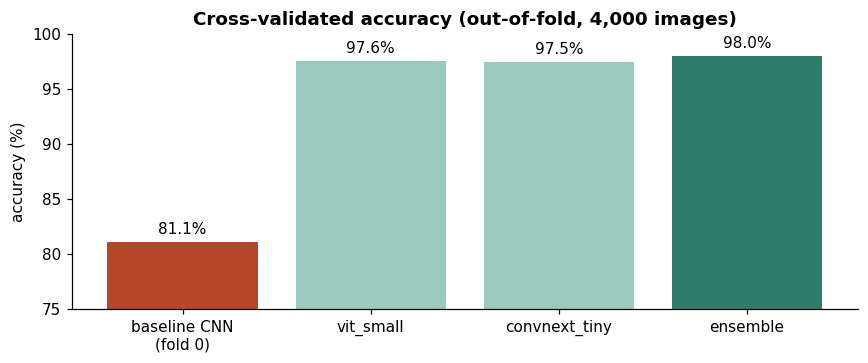

In [8]:
# Choose the final prediction by OOF accuracy: the ensemble is kept only if it beats the best single model
cands = {m: oof_probs[m] for m in MODELS} | {"ensemble (mean)": ens_oof}
scores = {m: (p.argmax(1) == y).mean() for m, p in cands.items()}
FINAL = max(scores, key=scores.get)
final_oof = cands[FINAL]
final_test = np.mean([test_probs[m] for m in MODELS], axis=0) if FINAL == "ensemble (mean)" else test_probs[FINAL]
cv_acc = scores[FINAL]
print(f"Final choice: {FINAL} | OOF accuracy {cv_acc:.4f} ({int(round((1 - cv_acc) * len(y)))} errors / {len(y)})")

fig, ax = plt.subplots(figsize=(8, 3.4))
base = cu.load_results().get("baseline_val_acc", {}).get("value", 0.811)
names = ["baseline CNN\n(fold 0)"] + [m.replace(" (mean)", "") for m in scores]
vals = [base] + list(scores.values())
bars = ax.bar(names, np.array(vals) * 100, color=["#B5482B"] + ["#9CC9BD"] * len(MODELS) + ["#2E7D6B"])
ax.bar_label(bars, labels=[f"{v:.1%}" for v in vals], padding=3)
ax.set_ylim(75, 100); ax.set_ylabel("accuracy (%)"); ax.set_title("Cross-validated accuracy (out-of-fold, 4,000 images)")
fig.tight_layout()
cu.save_figure(fig, "04_cv_accuracy", NOTEBOOK, caption="Out-of-fold accuracy of each final model and the ensemble vs the baseline.")
plt.show()

**Interpretation:**
- **Honest accuracy: 98.05% out-of-fold** (78 errors out of 4,000), from the ensemble of ViT-Small and ConvNeXt-Tiny. Every one of the 4,000 images was predicted by a model that never trained on it, so this is a fair estimate of accuracy on the 46,000 test images.
- **Single models:** ViT-Small 97.60%, ConvNeXt-Tiny 97.48%. That is close to, and slightly below, the 98.1% seen on fold 0 in notebook 03, confirming that the fold-0 figure carried a small selection bias, as expected.
- **Stable across folds:** per-fold accuracy ranges from 97.1% to 98.3% (standard deviation ≈ 0.4 points). The result does not depend on a lucky split.
- **The ensemble helps:** averaging the two architectures removes about 18% of the remaining errors (2.40% → 1.95% error versus the best single model). ViT (attention over image patches) and ConvNeXt (convolutions) make partly different mistakes. The ensemble was chosen because it had the best OOF accuracy.
- **Progress over the project:** 81.1% (CNN from scratch) → 96.4% (pretrained ViT, default settings) → 97.6% (tuned, 5-fold) → **98.05% (ensemble)**.

## 4 · Error analysis

Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/04_confusion_matrix.png


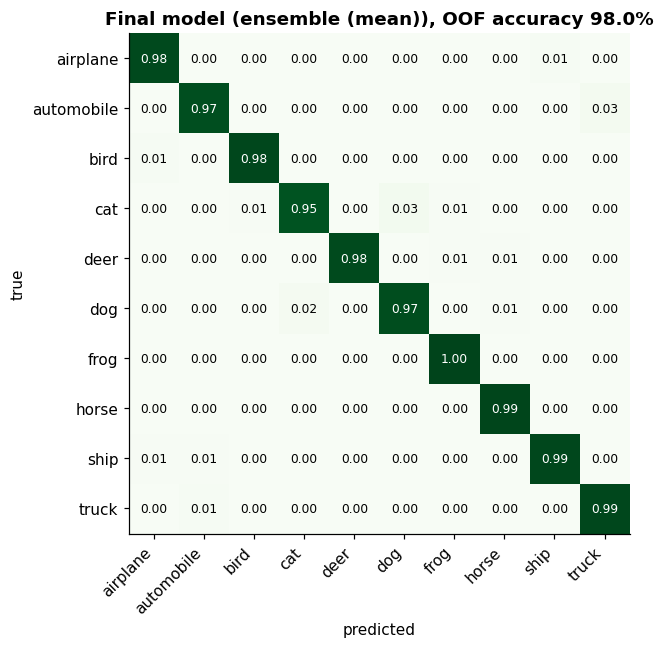

Table saved  -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/tables/04_classification_report.csv


,precision,recall,f1-score,support
airplane,0.978,0.982,0.980,400.00
automobile,0.982,0.968,0.975,400.00
bird,0.983,0.985,0.984,400.00
cat,0.977,0.952,0.965,400.00
deer,0.995,0.980,0.987,400.00
dog,0.965,0.970,0.968,400.00
frog,0.985,0.998,0.991,400.00
horse,0.983,0.995,0.989,400.00
ship,0.988,0.988,0.988,400.00
truck,0.971,0.988,0.979,400.00


In [9]:
pred = final_oof.argmax(1)
cm = confusion_matrix(y, pred, normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(10), cu.CLASSES, rotation=45, ha="right"); ax.set_yticks(range(10), cu.CLASSES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > .5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Final model ({FINAL}), OOF accuracy {cv_acc:.1%}")
fig.tight_layout()
cu.save_figure(fig, "04_confusion_matrix", NOTEBOOK, caption="Out-of-fold confusion matrix of the final model (row-normalised).")
plt.show()
rep = classification_report(y, pred, target_names=cu.CLASSES, digits=3, output_dict=True)
rep_df = pd.DataFrame(rep).T.round(3)
cu.save_table(rep_df.reset_index(names="class"), "04_classification_report", NOTEBOOK, caption="Per-class precision, recall and F1 (out-of-fold).")
rep_df

Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/04_confident_mistakes.png


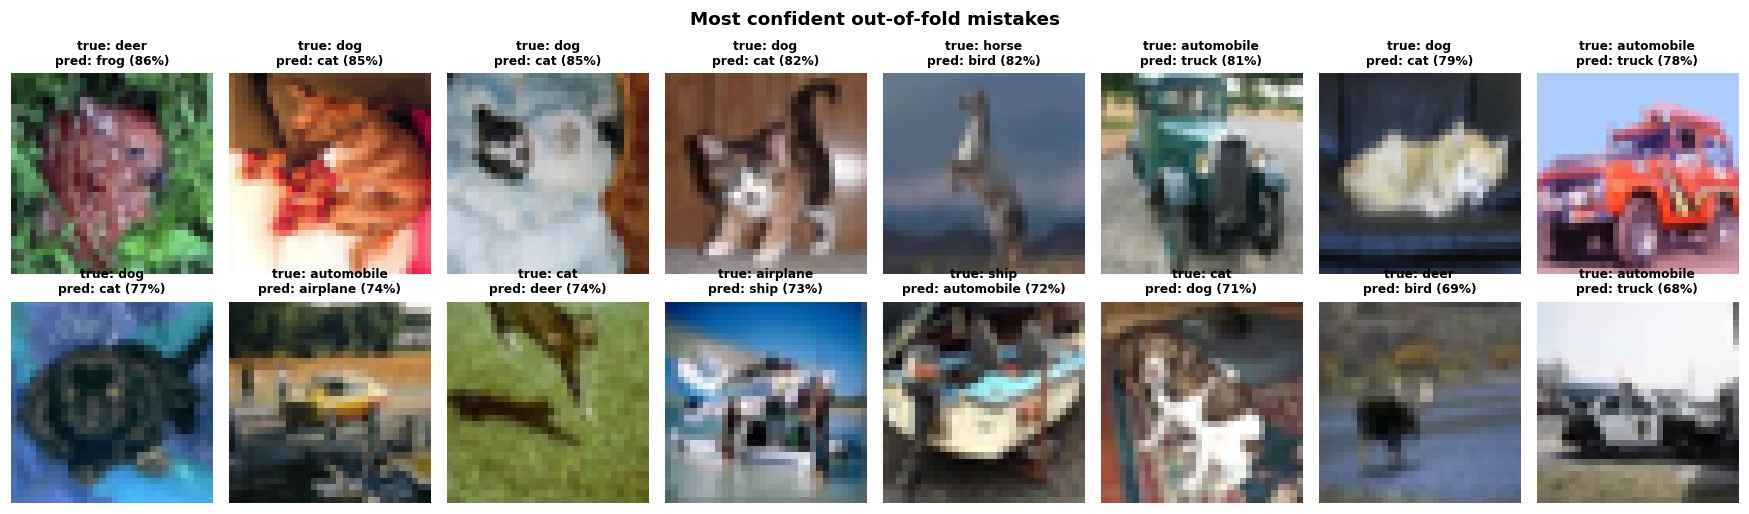

In [10]:
# The most confident mistakes: what does the model still get wrong?
wrong = np.where(pred != y)[0]
wrong = wrong[np.argsort(-final_oof[wrong].max(1))][:16]
fig, axes = plt.subplots(2, 8, figsize=(16, 4.8))
for ax, i in zip(axes.flat, wrong):
    ax.imshow(X[i], interpolation="nearest"); ax.axis("off")
    ax.set_title(f"true: {cu.CLASSES[y[i]]}\npred: {cu.CLASSES[pred[i]]} ({final_oof[i].max():.0%})", fontsize=8)
for ax in list(axes.flat)[len(wrong):]:
    ax.axis("off")
fig.suptitle("Most confident out-of-fold mistakes", fontweight="bold")
fig.tight_layout()
cu.save_figure(fig, "04_confident_mistakes", NOTEBOOK, caption="The 16 out-of-fold mistakes made with the highest confidence.")
plt.show()

Figure saved -> /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/figures/04_vit_fold0_history.png


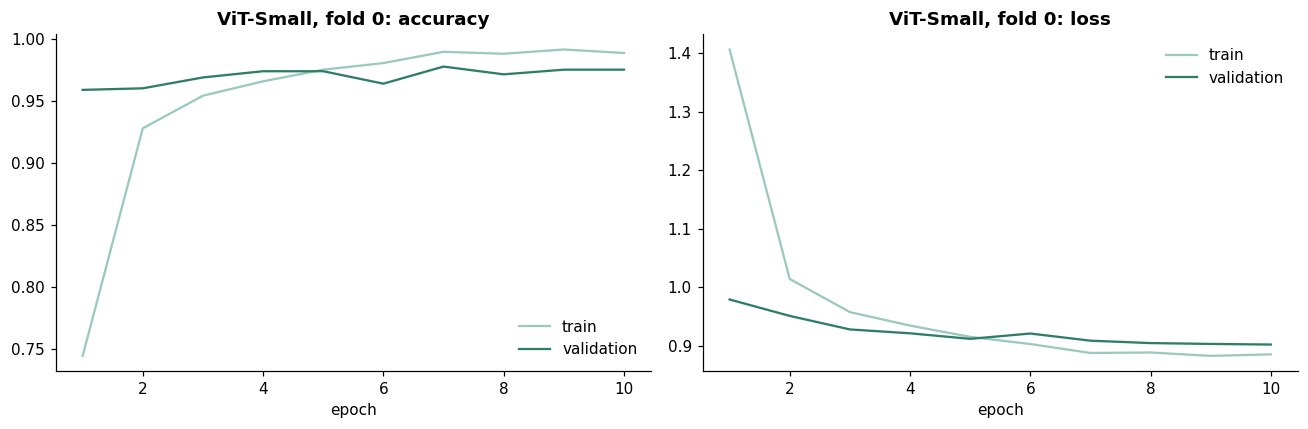

In [11]:
# Training curves of the main model on fold 0
h = pd.read_csv(os.path.join(PATHS["logs"], "history_vit_small_fold0.csv"))
fig = cu.plot_history(h, "ViT-Small, fold 0")
cu.save_figure(fig, "04_vit_fold0_history", NOTEBOOK, caption="Training curves of the ViT-Small model on fold 0.")
plt.show()

**Interpretation:**
- **Every class is now above 95% recall.** The hardest class is still **cat (95.2%)**, followed by automobile (96.8%) and dog (97.0%). In the baseline, cat recall was only 60%.
- **The remaining confusions are the semantically close pairs:** cat→dog (3%), dog→cat (2%) and automobile→truck (3%). The same pairs troubled the baseline, but at a far lower rate.
- **The most confident mistakes are mostly hard or ambiguous images,** not obvious failures: tiny, blurred or partial objects (a horse photographed from far away, a deer in grass), unusual viewpoints, and vehicles between classes (pick-up or jeep-like cars labelled automobile, predicted truck). Several images labelled "dog" look very cat-like even to a human at 32×32, suggesting a small amount of **label noise or genuine ambiguity** in the data. Some of the remaining 2% error is therefore hard to remove.
- **Training curves (ViT, fold 0):** validation accuracy is ~96% after the first epoch, because the pretrained features are already strong. It then rises to ~97.5% and stays flat, while validation loss decreases steadily without turning upward. With strong regularisation (label smoothing 0.2, weight decay 0.09, augmentation), the model shows **no harmful overfitting**, unlike the baseline (96% training vs 80% validation).

## 5 · Test predictions and submission file
The test probabilities of the chosen model(s) are averaged over all fold models (with TTA). The class with the highest probability is the prediction. The file keeps the **exact row order and columns of `Test.csv`** (`id`, `label`), with class names as labels.

In [12]:
np.save(os.path.join(PATHS["processed"], "test_probs_ensemble.npy"), final_test)
submission = test_df[["id"]].copy()
submission["label"] = np.array(cu.CLASSES)[final_test.argmax(1)]
assert len(submission) == len(test_df) and (submission["id"].values == test_df["id"].values).all()
assert submission["label"].isin(cu.CLASSES).all() and submission["label"].notna().all()
sub_path = os.path.join(PATHS["submission"], "submission.csv")
submission.to_csv(sub_path, index=False)
print("Saved", sub_path, submission.shape)

dist = submission["label"].value_counts().reindex(cu.CLASSES)
conf = final_test.max(1)
print("Predicted class shares (training data is exactly 10% each):")
print((dist / len(submission)).round(3).to_string())
print(f"\nMean confidence {conf.mean():.3f} | share of test images predicted with >95% confidence: {(conf > 0.95).mean():.1%}")
submission.head()

Saved /content/drive/MyDrive/DSA4050/cat2-image-classification/outputs/submission/submission.csv (46000, 2)
Predicted class shares (training data is exactly 10% each):
label
airplane      0.101
automobile    0.101
bird          0.099
cat           0.100
deer          0.101
dog           0.099
frog          0.101
horse         0.100
ship          0.100
truck         0.099

Mean confidence 0.791 | share of test images predicted with >95% confidence: 0.0%


,id,label
0,33680,truck
1,24631,deer
2,34739,dog
3,15922,truck
4,44282,automobile


In [13]:
cu.log_result("final_model", FINAL, NOTEBOOK)
cu.log_result("cv_oof_accuracy", round(float(cv_acc), 4), NOTEBOOK)
for m, s in scores.items():
    cu.log_experiment(f"final_5fold_{m.split(' ')[0]}", {"oof_acc_5fold": round(float(s), 4), "img_size": IMG_SIZE},
                      NOTEBOOK, params={"epochs": EPOCHS, "tta": "hflip"}, notes="5-fold CV, last-epoch weights")
cu.project_summary()

Result logged: final_model = ensemble (mean)
Result logged: cv_oof_accuracy = 0.9805
Experiment logged: final_5fold_vit_small -> {'oof_acc_5fold': 0.976, 'img_size': 224}
Experiment logged: final_5fold_convnext_tiny -> {'oof_acc_5fold': 0.9748, 'img_size': 224}
Experiment logged: final_5fold_ensemble -> {'oof_acc_5fold': 0.9805, 'img_size': 224}
Project root : /content/drive/MyDrive/DSA4050/cat2-image-classification
Figures      : 14
Tables       : 11
Models       : 1
Results      : 30
Experiments  : 8


## Findings for the write-up
1. **Final model:** an ensemble of **10 networks**, 5 ViT-Small + 5 ConvNeXt-Tiny (one per fold), all ImageNet-21k/22k pretrained and fine-tuned at 224×224 with the Optuna settings, predicting with horizontal-flip TTA.
2. **Cross-validated accuracy: 98.05%** (out-of-fold, 4,000 images). ViT alone 97.60%, ConvNeXt alone 97.48%. Fold-to-fold standard deviation ≈ 0.4 points.
3. **Per class:** all classes ≥ 95% recall. Cat (95.2%) is hardest; the main confusions are cat↔dog and automobile→truck.
4. **Submission:** `outputs/submission/submission.csv`, 46,000 rows in `Test.csv` order. The predicted classes are almost exactly 10% each (9.9–10.1%), matching the balanced training data, which is a good sign the predictions are not biased toward any class.
5. **Note on confidence:** the average predicted probability is 0.79 and almost no prediction exceeds 0.95. This is **caused by label smoothing (0.2)**: the model is trained to give the correct class about 0.82, not 1.0. It does not mean the model is unsure; accuracy is still 98%.

**Next notebook:** `05_submission_and_report.ipynb`: final checks on the submission and the written description of the whole method.